# Clase 8 — Selección estadística de variables predictoras

**Duración:** 90 minutos · **Organización:** dos grupos.

Una entidad quiere priorizar a qué clientes contactar para recordarles una cuota y ofrecerles orientación. Una persona revisará cada caso; el modelo no aprueba ni rechaza créditos.

**Desafío:** partir de un modelo base, elegir columnas con evidencia estadística y conseguir al menos **80% de recall en validación**. Busquen mejorar también la precisión del modelo base. Al final, evalúen la selección una sola vez con los datos de prueba.

## Antes de ejecutar: guía para entender el ejercicio

### 1. ¿Qué significa seleccionar variables?

Una variable predictora es una columna que se ofrece al modelo para estimar una etiqueta. **Seleccionar variables** consiste en escoger algunas de las columnas existentes. No es crear columnas nuevas ni transformar muchas columnas en componentes, como hace PCA.

Hay tres familias de métodos de selección:

| Familia | Cómo propone variables | Ejemplo o límite |
|---|---|---|
| **Filtro** | Mide una propiedad de cada columna o su asociación con la etiqueta, sin entrenar el modelo. | Spearman, chi-cuadrado y V de Cramér. Es rápido, pero suele evaluar cada variable por separado. |
| **Wrapper** | Prueba subconjuntos distintos entrenando y evaluando un modelo. | RFE. Puede considerar el efecto conjunto, pero requiere más cálculos y una validación cuidadosa. |
| **Integrado al modelo** | El propio entrenamiento reduce o puntúa el uso de variables. | Regularización L1 o importancia en árboles. La importancia depende del modelo y no prueba causalidad. |

En esta práctica usamos **filtros para proponer candidatas** y después comprobamos si la selección sirve para este modelo en validación. Una columna con asociación alta no necesariamente mejora el resultado: puede repetir información de otra, tener categorías escasas o no aportar al modelo.

### 2. ¿Cómo interpretar los resultados de asociación?

Las asociaciones describen cómo se relacionan dos columnas en los datos observados. No demuestran que una columna cause otra ni que esa relación se mantenga en datos futuros.

#### Si la columna tiene números: Spearman

**La pregunta que responde:** cuando ordenamos los registros por una columna numérica —por ejemplo, de menor a mayor ingreso—, ¿los casos con `moroso = 1` aparecen más hacia un extremo?

El resultado, llamado `rho`, va de −1 a 1:

- **Cerca de 1:** los valores altos suelen aparecer junto con `moroso = 1`.
- **Cerca de −1:** los valores altos suelen aparecer junto con `moroso = 0`.
- **Cerca de 0:** no se ve una tendencia clara hacia un lado.

Cuanto más cerca está de −1 o 1, más clara es la tendencia. Por ejemplo, `rho = −0.25` indica una tendencia débil hacia valores altos en registros con `moroso = 0`. No significa que el riesgo baje 25%. Tampoco alcanza para descartar una columna: podría servir al combinarse con otras.

#### Si la columna tiene categorías: chi-cuadrado y V de Cramér

**La pregunta que responde chi-cuadrado:** ¿la proporción de `moroso = 1` parece parecida en todas las categorías, o cambia entre ellas?

Por ejemplo, se pueden comparar los productos. Si en un producto hay 4 morosos de cada 10 registros y en otro hay 1 de cada 10, las proporciones observadas son distintas. Chi-cuadrado calcula si una diferencia así sería poco habitual si, en realidad, el producto y `moroso` no tuvieran relación.

La tabla muestra el **p valor** de esa prueba. Como referencia, suele mirarse si es menor que 0.05. Un p valor pequeño sugiere que la diferencia merece atención; **no** demuestra que el producto cause la mora, no dice cuán grande es la diferencia y no garantiza que el modelo vaya a mejorar.

**La pregunta que responde V de Cramér:** ¿qué tan marcada es la diferencia entre las categorías? Su valor va de 0 a 1: cerca de 0 indica poca asociación; un valor mayor indica una asociación más marcada. No hay un número mágico que diga si una columna sirve. Comparen los valores entre sí y revisen también cuántos registros hay en cada categoría.

#### ¿Por qué miramos los recuentos esperados?

Chi-cuadrado calcula cuántos casos esperaría encontrar en cada combinación si la categoría y `moroso` no estuvieran relacionados. Cuando esos recuentos esperados son muy pequeños en muchas combinaciones, el p valor puede ser poco confiable.

La tabla informa el recuento esperado más bajo y qué porcentaje de combinaciones tiene menos de 5. También miren el tamaño real de cada grupo: si una categoría tiene solo unos pocos registros, uno o dos casos pueden cambiar mucho su proporción.

**Qué hacer con estos resultados:** úsenlos para proponer qué columnas probar. Son una primera revisión de cada columna por separado. Después comparen el modelo en validación para saber si la selección ayuda en conjunto.

**Ejemplo de lectura:** si una categoría tiene una proporción alta de `moroso = 1` pero pocas filas, describan ambas cosas: “la proporción observada es alta” y “hay pocos casos, así que la estimación es incierta”. No concluyan que esa categoría causa la mora.

### 3. ¿Cómo evaluamos si una selección ayuda al modelo?

Los filtros son una primera mirada **variable por variable**. El modelo, en cambio, usa las columnas elegidas en conjunto. Para evaluar esa selección, comparamos el mismo modelo base con el modelo elegido y mantenemos fijo el preprocesamiento y la partición de datos.

La clase positiva es `moroso = 1`. La matriz de confusión organiza los casos reales en filas y las predicciones en columnas:

- **Recall** = positivos detectados / todos los positivos reales. Si el recall es 0.80 en validación, el modelo detectó 8 de cada 10 casos etiquetados como morosos en esa muestra; dejó escapar 2 de cada 10.
- **Precisión** = positivos reales detectados / todos los casos que el modelo marcó como positivos. Si la precisión es 0.50, la mitad de las alertas correspondió a registros con `moroso = 1`.

La meta es `recall ≥ 0.80` en validación. Para lograrla, el código ajusta el **umbral** de cada modelo usando solo esa muestra y luego compara la precisión. El modelo produce probabilidades; el umbral las convierte en 0 o 1. Al bajarlo, normalmente se detectan más positivos, junto con más falsas alertas. Por eso variables predictoras y umbral son decisiones distintas.

La selección habrá mejorado la comparación si alcanza la meta de recall y logra mayor precisión que el modelo base. Si no lo consigue, prueben otra selección razonada; si los datos no muestran una mejora, registren ese resultado. La asociación estadística por sí sola no garantiza el objetivo.

### 4. ¿Por qué separamos los datos?

- **Entrenamiento:** el modelo aprende patrones y el preprocesamiento aprende, por ejemplo, medianas, escalas y categorías.
- **Validación:** el grupo propone variables y ajusta el umbral. Como se consulta varias veces, una selección puede adaptarse demasiado a esta muestra.
- **Prueba:** queda reservada hasta el final. Se usa una sola vez para ver si el resultado de validación se sostuvo en otra muestra.

La prueba no se usa para elegir columnas ni umbrales. Aunque validación alcance 80% de recall, la prueba podría quedar por debajo. Si eso ocurre, repórtenlo: no cambien decisiones mirando la prueba.

### 5. ¿Qué columnas se pueden considerar?

La etiqueta es `moroso`. Para esta práctica, las candidatas son `ingresos`, `edad`, `Cuota`, `cant_cuotas`, `Monto_Otorgado`, `PRODUCTO`, `PROVINCIA` y `bancarizado`.

No incluyan `ID`, la propia etiqueta, ni columnas de atraso, mora o deuda que podrían contener información posterior al resultado. El archivo no documenta el momento en que se registró cada dato: la disponibilidad de las candidatas se toma como un supuesto didáctico y habría que confirmarla antes de interpretar un uso real.

## Desafío y recorrido

**Distribución sugerida:** 20 minutos para leer, conversar y comprender los conceptos; 50 minutos para completar el recorrido, comparar resultados y preparar una explicación breve.

Sigan las celdas en orden. Las celdas de exploración muestran evidencia; después, el grupo completa `variables_elegidas` con las columnas que quiere probar. El código mantiene fijo el tipo de modelo, el preprocesamiento y la partición para que la comparación dependa de las variables elegidas.

Al final, cada grupo comparte en dos minutos:

1. Qué columnas eligió y qué evidencia consideró.
2. Si logró `recall ≥ 0.80` en validación y cómo quedó la precisión frente al modelo base.
3. Qué resultado obtuvo en prueba y qué dato de las columnas falta confirmar.

## Recorrido práctico — ejecutar en orden

### 1. Cargar los datos y mirar la etiqueta

La celda busca `dataset_credito.csv` en las ubicaciones habituales. Si trabajan en Colab y no aparece, suban el archivo al entorno.

In [38]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import chi2_contingency
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

rutas = [
    Path("modulo_5/dataset_credito.csv"),
    Path("dataset_credito.csv"),
    Path("../modulo_3/dataset_credito.csv"),
]
ruta = next((p for p in rutas if p.exists()), None)
if ruta is None:
    raise FileNotFoundError(
        "No encuentro dataset_credito.csv. Subilo al entorno o abrí el notebook desde modulo_5/."
    )

datos = pd.read_csv(ruta)
if "moroso" not in datos.columns:
    raise ValueError("El archivo debe incluir la columna moroso.")

display(datos.head(3))
print("Filas y columnas:", datos.shape)
print("\nRegistros por clase de moroso:")
display(datos["moroso"].value_counts(dropna=False).sort_index().rename("cantidad").to_frame())

,ID,ingresos,edad,provincia_codigo,bancarizado,BCRA_Peor_Situacion,Cantidad_consultas_7_dias,Compromisos_Mensual,Endeudamiento_Externo,Nivel_Socioeconomico,...,autonomo,Es_jubilado,relacion_dependencia,dias_atraso,Cuota,cant_cuotas,Monto_Otorgado,PRODUCTO,PROVINCIA,moroso
0,1,35000.0,35,X,1,1,1.0,9976.0,170000.0,4,...,F,F,UNIVERSIDAD NACIONAL DE CORDOBA ...,143,8957.00,12,50000.0,DS_SUCURSAL_ORO,CORDOBA,1
1,2,50000.0,24,B,1,3,0.0,16807.0,236000.0,4,...,F,F,POLICIA FEDERAL ARGENTINA ...,174,6874.49,9,25000.0,DS_BASICO,BUENOS AIRES,1
2,3,50000.0,42,X,1,1,5.0,42959.0,683343.0,3,...,F,F,MINISTERIO DE EDUCACION ...,0,4191.93,12,23400.0,DS_SUCURSAL_ORO,CORDOBA,0


Filas y columnas: (1190, 26)

Registros por clase de moroso:


,cantidad
moroso,
0,921
1,269


**Anoten antes de seguir:** ¿qué valor de `moroso` aparece menos? ¿Qué consecuencia tendría no detectar parte de esos casos?

### 2. Separar entrenamiento, validación y prueba

La división es estratificada: cada parte conserva una proporción parecida de `moroso = 1`. La lista acota el ejercicio a columnas cuyo significado podemos discutir; las demás quedan afuera mientras no sepamos si están disponibles y qué representan.

In [39]:
numericas = ["ingresos", "edad", "Cuota", "cant_cuotas", "Monto_Otorgado"]
categoricas = ["PRODUCTO", "PROVINCIA", "bancarizado"]
candidatas = numericas + categoricas

faltan = sorted(set(candidatas + ["moroso"]) - set(datos.columns))
if faltan:
    raise ValueError(f"Faltan columnas necesarias en el CSV: {faltan}")

resto, prueba = train_test_split(
    datos, test_size=0.20, stratify=datos["moroso"], random_state=42
)
entrenamiento, validacion = train_test_split(
    resto, test_size=0.25, stratify=resto["moroso"], random_state=42
)

print(
    "Filas — entrenamiento:", len(entrenamiento),
    "| validación:", len(validacion),
    "| prueba reservada:", len(prueba),
)
print("\nProporción moroso = 1 en cada parte:")
display(
pd.DataFrame({
    "Entrenamiento": entrenamiento["moroso"].value_counts(normalize=True),
    "Validación": validacion["moroso"].value_counts(normalize=True),
    "Prueba": prueba["moroso"].value_counts(normalize=True),
}).sort_index().round(3)
)

inventario = pd.DataFrame({
    "tipo": datos[candidatas].dtypes.astype(str),
    "faltantes": datos[candidatas].isna().sum(),
    "valores distintos": datos[candidatas].nunique(dropna=True),
})
display(inventario)

Filas — entrenamiento: 714 | validación: 238 | prueba reservada: 238

Proporción moroso = 1 en cada parte:


,Entrenamiento,Validación,Prueba
moroso,,,
0,0.775,0.773,0.773
1,0.225,0.227,0.227


,tipo,faltantes,valores distintos
ingresos,float64,0,659
edad,int64,0,61
Cuota,float64,0,672
cant_cuotas,int64,0,9
Monto_Otorgado,float64,0,345
PRODUCTO,object,0,7
PROVINCIA,object,0,23
bancarizado,int64,0,2


**Conversen:** ¿hay columnas con muchos faltantes o categorías? ¿Qué habría que averiguar sobre el significado o el momento de registro de alguna candidata?

### 3. Explorar asociaciones solo en entrenamiento

#### Numéricas: Spearman

El cálculo usa solo entrenamiento. El gráfico muestra dirección e intensidad de asociación con `moroso`; no es una clasificación de columnas “buenas” y “malas”.

Spearman: intensidad de asosiación con moroso


,Spearman
Monto_Otorgado,-0.223
ingresos,-0.206
edad,-0.179
Cuota,-0.176
cant_cuotas,0.103


El signo indica dirección: 
 > uno positivo señala que los valores más altos tienden a aparecer junto con `moroso = 1`; 
 > uno negativo, que tienden a aparecer con `moroso = 0`


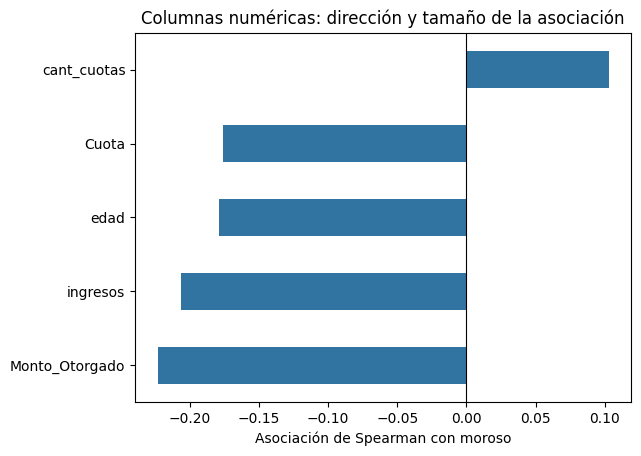

In [50]:
rho = (
    entrenamiento[numericas + ["moroso"]]
    .corr(method="spearman")["moroso"]
    .drop("moroso")
    .sort_values()
)
print("Spearman: intensidad de asosiación con moroso")

display(rho.rename("Spearman").to_frame().round(3))
print("El signo indica dirección: \n > uno positivo señala que los valores más altos tienden a aparecer junto con `moroso = 1`; \n > uno negativo, que tienden a aparecer con `moroso = 0`")
rho.plot.barh(color="#3274a1")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Asociación de Spearman con moroso")
plt.title("Columnas numéricas: dirección y tamaño de la asociación")
plt.show()

**Registren una observación y una duda:** ¿qué columnas muestran una asociación mayor? ¿Una asociación pequeña alcanza para descartar una variable?

#### Categóricas: chi-cuadrado y V de Cramér

La tabla muestra la V de Cramér, la frecuencia esperada más baja y qué proporción de celdas tiene un valor esperado menor que 5. Si hay muchas celdas pequeñas, interpreten el resultado con cautela.

In [41]:
resumen_categoricas = []
for columna in categoricas:
    tabla = pd.crosstab(
        entrenamiento[columna].fillna("Sin dato"), entrenamiento["moroso"]
    )
    chi2, p_valor, _, esperadas = chi2_contingency(tabla)
    divisor = tabla.to_numpy().sum() * min(tabla.shape[0] - 1, tabla.shape[1] - 1)
    v_cramer = np.sqrt(chi2 / divisor) if divisor > 0 else np.nan
    resumen_categoricas.append({
        "columna": columna,
        "V de Cramér": v_cramer,
        "p valor chi-cuadrado": p_valor,
        "esperada mínima": esperadas.min(),
        "% esperadas < 5": (esperadas < 5).mean(),
        "categorías": tabla.shape[0],
    })

display(pd.DataFrame(resumen_categoricas).set_index("columna").round(3))

,V de Cramér,p valor chi-cuadrado,esperada mínima,% esperadas < 5,categorías
columna,,,,,
PRODUCTO,0.423,0.0,4.735,0.071,7
PROVINCIA,0.277,0.0,0.451,0.435,23
bancarizado,0.204,0.0,56.598,0.000,2


La tabla resume asociaciones generales. Para `PRODUCTO`, revisen también la proporción de morosos y la cantidad de filas en cada grupo; una proporción basada en pocos casos merece cautela.

,proporcion,cantidad
PRODUCTO,,
DS_BOT_ORO,0.00,24
DS_REFINANCIACION,0.03,215
DS_PREMIUM,0.15,41
DS_SUCURSAL_ORO,0.22,218
DS_PLATA,0.43,21
DS_BASICO,0.45,170
DS_SUCURSAL_PLATA,0.56,25


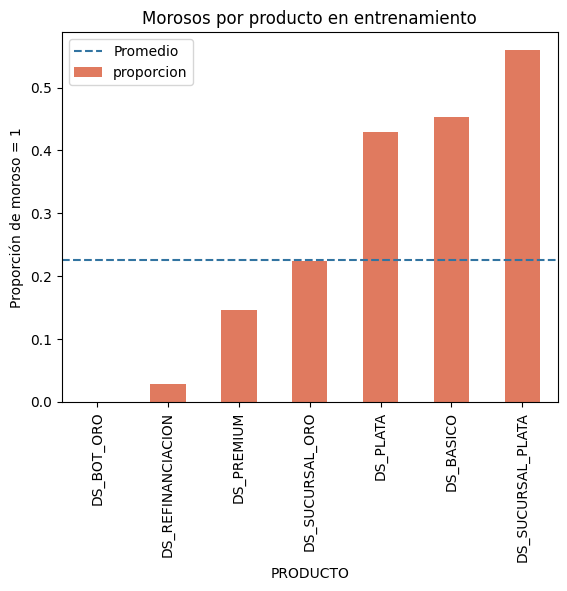

In [42]:
por_producto = (
    entrenamiento.groupby("PRODUCTO")["moroso"]
    .agg(proporcion="mean", cantidad="count")
    .sort_values("proporcion")
)
display(por_producto.round(2))
por_producto["proporcion"].plot.bar(color="#e07a5f")
plt.axhline(entrenamiento["moroso"].mean(), color="#3274a1", linestyle="--", label="Promedio")
plt.ylabel("Proporción de moroso = 1")
plt.title("Morosos por producto en entrenamiento")
plt.legend()
plt.show()

**Decisión del grupo:** anoten qué variables probarían y justifiquen la selección con los resultados, los tamaños de los grupos y el significado de las columnas. No usen la prueba para decidir.

### 4. Completar la selección

El modelo base usa `cant_cuotas` y `PROVINCIA`. Ahora completen la lista con una o más columnas candidatas, según lo conversado. No incluyan `moroso`, `ID` ni columnas de atraso, mora o deuda.

In [51]:
print("Candidatas disponibles:", candidatas)

Candidatas disponibles: ['ingresos', 'edad', 'Cuota', 'cant_cuotas', 'Monto_Otorgado', 'PRODUCTO', 'PROVINCIA', 'bancarizado']


In [53]:
variables_iniciales = ["cant_cuotas", "PROVINCIA"]

# EDITEN esta lista con las columnas que decidió probar el grupo.
# Ejemplo de formato: ["ingresos", "PRODUCTO"]
variables_elegidas = []

print("Selección del grupo:", variables_elegidas)

Selección del grupo: []


### 5. Entrenar y comparar en validación

Se conserva el mismo modelo base para ambas selecciones: una red pequeña con 8 neuronas en una capa oculta. El preprocesamiento se aprende con entrenamiento y se reutiliza en validación. Para cada selección, el código encuentra en validación el umbral más alto que alcanza el recall mínimo de 0,80; luego compara precisión a esa meta.

In [44]:
if not variables_elegidas:
    raise ValueError("Completen variables_elegidas con al menos una columna y vuelvan a ejecutar esta celda.")
if len(set(variables_elegidas)) != len(variables_elegidas):
    raise ValueError("No repitan columnas en variables_elegidas.")
if not set(variables_elegidas).issubset(candidatas):
    raise ValueError(f"Usen solo estas columnas candidatas: {candidatas}")


def armar_modelo(columnas):
    nums = [columna for columna in columnas if columna in numericas]
    cats = [columna for columna in columnas if columna in categoricas]
    preparacion = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), nums),
        (
            make_pipeline(
                SimpleImputer(strategy="most_frequent"),
                OneHotEncoder(handle_unknown="ignore"),
            ),
            cats,
        ),
    )
    clasificador = MLPClassifier(
        hidden_layer_sizes=(8,), random_state=42, max_iter=1000
    )
    return make_pipeline(preparacion, clasificador)


def umbral_para_recall(y_real, probabilidades, meta=0.80):
    _, recall, umbrales = precision_recall_curve(y_real, probabilidades)
    posibles = np.flatnonzero(recall[:-1] >= meta)
    if len(posibles) == 0:
        return 0.0
    return umbrales[posibles[-1]]


modelos = {}
umbrales = {}
resultados = []
for nombre, columnas in [
    ("Base", variables_iniciales),
    ("Elegida", variables_elegidas),
]:
    modelo = armar_modelo(columnas)
    modelo.fit(entrenamiento[columnas], entrenamiento["moroso"])
    probabilidades = modelo.predict_proba(validacion[columnas])[:, 1]
    umbral = umbral_para_recall(validacion["moroso"], probabilidades)
    predicciones = probabilidades >= umbral

    modelos[nombre] = modelo
    umbrales[nombre] = umbral
    resultados.append({
        "Modelo": nombre,
        "Variables": ", ".join(columnas),
        "Umbral en validación": umbral,
        "Recall en validación": recall_score(validacion["moroso"], predicciones),
        "Precisión en validación": precision_score(
            validacion["moroso"], predicciones, zero_division=0
        ),
    })

tabla_resultados = pd.DataFrame(resultados).set_index("Modelo")
display(tabla_resultados.round(3))

,Variables,Umbral en validación,Recall en validación,Precisión en validación
Modelo,,,,
Base,"cant_cuotas, PROVINCIA",0.156,0.815,0.262
Elegida,"cant_cuotas, PROVINCIA",0.156,0.815,0.262


**Lean la tabla y decidan si iterar:** ¿la selección cumple el recall mínimo? ¿Mejoró la precisión respecto del modelo base? Si no, vuelvan a la celda `variables_elegidas`, prueben otra combinación razonada y vuelvan a ejecutar la comparación. Si no encuentran una mejora, registren el mejor resultado obtenido y expliquen el límite.

### 6. Revisar el umbral de la selección elegida

La línea horizontal marca la meta de recall y la vertical, el umbral seleccionado con validación. Observen qué pasa con la precisión cuando el umbral cambia.

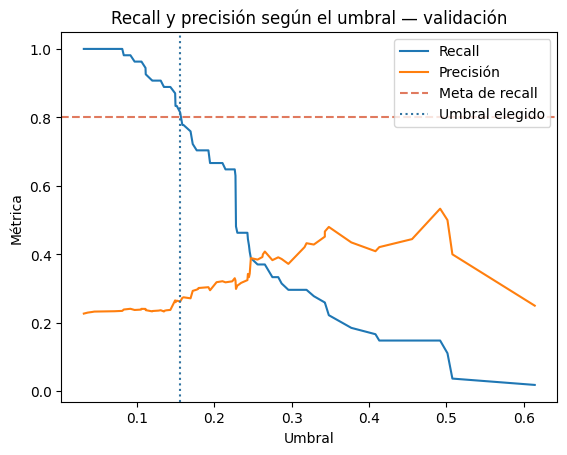

In [45]:
prob_validacion = modelos["Elegida"].predict_proba(
    validacion[variables_elegidas]
)[:, 1]
precision, recall, umbrales_grafico = precision_recall_curve(
    validacion["moroso"], prob_validacion
)
umbral_elegido = umbrales["Elegida"]

plt.plot(umbrales_grafico, recall[:-1], label="Recall")
plt.plot(umbrales_grafico, precision[:-1], label="Precisión")
plt.axhline(0.80, color="#e07a5f", linestyle="--", label="Meta de recall")
plt.axvline(umbral_elegido, color="#3274a1", linestyle=":", label="Umbral elegido")
plt.xlabel("Umbral")
plt.ylabel("Métrica")
plt.title("Recall y precisión según el umbral — validación")
plt.legend()
plt.show()

**Antes de seguir:** expliquen con sus palabras por qué el umbral no es una variable predictora y qué intercambio observan entre recall y precisión.

### 7. Evaluación final en prueba

Esta es la consulta final a la prueba reservada. No vuelvan a cambiar las variables ni el umbral después de ver este resultado.

Umbral elegido solo con validación: 0.156
Recall en prueba: 0.741
Precisión en prueba: 0.247


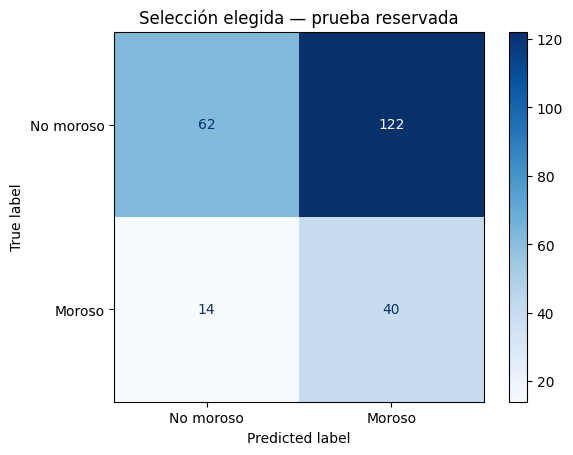

In [46]:
prob_prueba = modelos["Elegida"].predict_proba(prueba[variables_elegidas])[:, 1]
pred_prueba = prob_prueba >= umbral_elegido

print("Umbral elegido solo con validación:", round(float(umbral_elegido), 3))
print("Recall en prueba:", round(recall_score(prueba["moroso"], pred_prueba), 3))
print(
    "Precisión en prueba:",
    round(precision_score(prueba["moroso"], pred_prueba, zero_division=0), 3),
)
ConfusionMatrixDisplay.from_predictions(
    prueba["moroso"],
    pred_prueba,
    display_labels=["No moroso", "Moroso"],
    cmap="Blues",
)
plt.title("Selección elegida — prueba reservada")
plt.show()

## Cierre

Cada grupo comparte en dos minutos:

1. Las columnas seleccionadas y la evidencia que usó para elegirlas.
2. El recall y la precisión de la selección frente al modelo base en validación.
3. El resultado en prueba y una limitación o dato que todavía necesita confirmar.

Distingan **lo que muestran los resultados**, **la interpretación** y **lo que todavía no sabemos**. Este archivo no documenta el origen, el período ni el momento de captura de las columnas; por eso los resultados describen esta práctica y no demuestran cómo funcionaría el modelo con datos futuros.

Si usan inteligencia artificial, pídanle que explique una tabla o un gráfico concreto y comprueben la explicación contra la salida ejecutada. No acepten métricas que el notebook no haya calculado.